# Configuración de rutas e importación

In [1]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Subir un nivel hacia la raíz del proyecto para poder importar 'src'
project_root = os.path.abspath("..")
if project_root not in sys.path:
    sys.path.append(project_root)

from src.metrics.difficulty import DifficultyEvaluator
from src.optimizer.reducer import IterativePianoReducer
from src.utils.generator import build_complex_ensemble_piece
from src.utils.midi_exporter import export_score_to_csv, export_score_to_midi

DATA_DIR = os.path.join(project_root, "data")
os.makedirs(DATA_DIR, exist_ok=True)
print("Módulos cargados correctamente. Carpeta de datos:", DATA_DIR)

Módulos cargados correctamente. Carpeta de datos: c:\Users\Medin\Downloads\proyecto_machine_tesis\data


# Generación canción y evaluación inicial

In [2]:
# Generar pieza polifónica compleja y exportar versión original
original_score = build_complex_ensemble_piece()
export_score_to_csv(original_score, os.path.join(DATA_DIR, "00_original_compleja.csv"))
export_score_to_midi(original_score, os.path.join(DATA_DIR, "00_original_compleja.mid"))

evaluator = DifficultyEvaluator(sigma_p=5.5, epsilon=4e-4, delta_t=1.0)
reducer = IterativePianoReducer(evaluator=evaluator, kappa=2.2, decay_lambda=0.85, max_iter=50)

print(f"Total de notas en la pieza original: {len(original_score)}")

Total de notas en la pieza original: 136


# Ejecución por niveles y tabla comparativa

In [3]:
niveles = {
    "1. Facil (Principiante)": (
        12.0,
        12.0,
        22.0,
    ),  # Umbral muy estricto (borra muchas notas)
    "2. Intermedio": (
        25.0,
        25.0,
        35.0,
    ),  # Umbral moderado
    "3. Avanzado (Fiel)": (
        45.0,
        45.0,
        60.0,
    ),  # Umbral flexible (conserva casi todo)
}

partituras_generadas = {"0. Original": original_score}
filas_resumen = []

# Evaluar original respecto al umbral intermedio como referencia
stats_orig = evaluator.summarize_metrics(original_score, (25.0, 25.0, 35.0))
filas_resumen.append({"Versión": "0. Original (Sin reducir)", **stats_orig})

# Reducir para cada nivel
for idx, (nombre, umbral) in enumerate(niveles.items(), start=1):
  score_red = reducer.reduce(original_score, target_difficulty=umbral, label=nombre)
  partituras_generadas[nombre] = score_red

  stats = evaluator.summarize_metrics(score_red, umbral)
  filas_resumen.append({"Versión": nombre, **stats})

  slug = nombre.split()[1].lower()
  export_score_to_csv(score_red, os.path.join(DATA_DIR, f"0{idx}_reducida_{slug}.csv"))
  export_score_to_midi(score_red, os.path.join(DATA_DIR, f"0{idx}_reducida_{slug}.mid"))

df_resumen = pd.DataFrame(filas_resumen)
df_resumen

,Versión,total_notes,mean_DB,max_DB,out_of_range_pct,add_note_pct
0,0. Original (Sin reducir),136,138.05,163.77,100.0,240.0
1,1. Facil (Principiante),69,47.09,75.57,94.2,86.5
2,2. Intermedio,69,47.09,75.57,66.7,86.5
3,3. Avanzado (Fiel),69,45.47,75.57,27.5,86.5


# Visualización de la curva de dificultad y Piano Roll

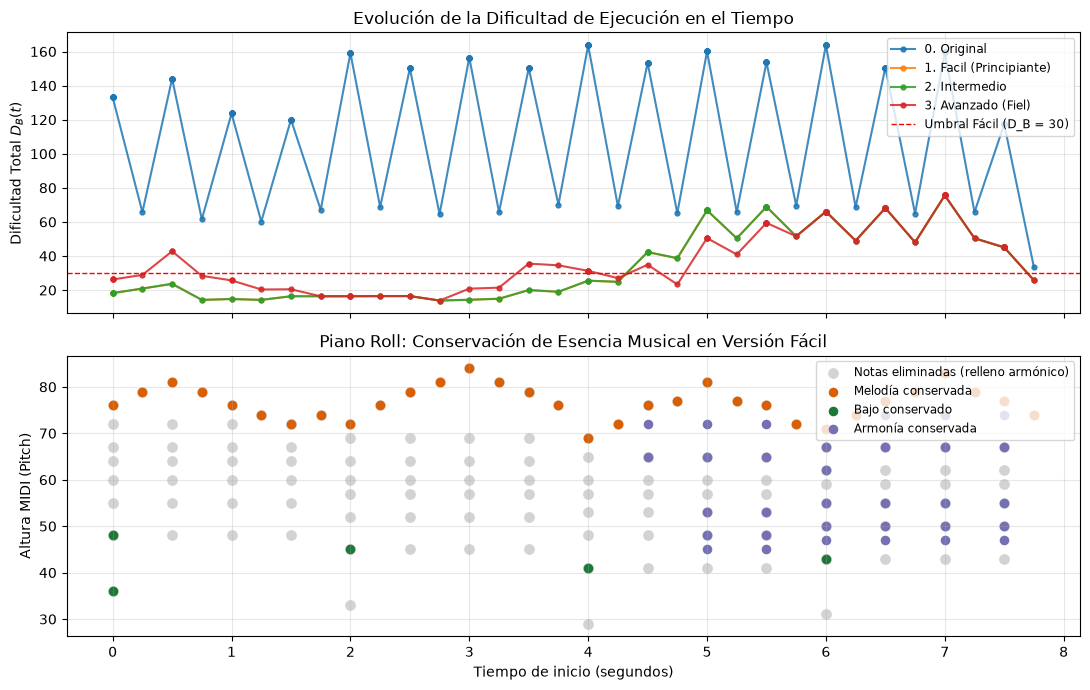

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# 1. Curva de dificultad total D_B(t) a lo largo del tiempo
for nombre, sc in partituras_generadas.items():
    detalles = evaluator.compute_note_difficulties(sc)
    tiempos = [d[0].onset for d in detalles]
    d_b_vals = [d[3] for d in detalles]
    axes[0].plot(tiempos, d_b_vals, marker="o", markersize=3.5, label=nombre, alpha=0.85)

axes[0].axhline(30.0, color="red", linestyle="--", linewidth=1, label="Umbral Fácil (D_B = 30)")
axes[0].set_ylabel("Dificultad Total $D_B(t)$")
axes[0].set_title("Evolución de la Dificultad de Ejecución en el Tiempo")
axes[0].legend(loc="upper right", fontsize=8.5)
axes[0].grid(True, alpha=0.3)

# 2. Comparación tipo Piano Roll: Original vs. Reducción Fácil
sc_facil = partituras_generadas["1. Facil (Principiante)"]
axes[1].scatter(
    [n.onset for n in original_score.notes],
    [n.pitch for n in original_score.notes],
    color="lightgray", s=45, label="Notas eliminadas (relleno armónico)"
)

colores_rol = {"melody": "#d95f02", "bass": "#1b7837", "harmony": "#7570b3"}
for rol, etiqueta in [("melody", "Melodía conservada"), ("bass", "Bajo conservado"), ("harmony", "Armonía conservada")]:
    notas_rol = [n for n in sc_facil.notes if n.role == rol]
    axes[1].scatter(
        [n.onset for n in notas_rol],
        [n.pitch for n in notas_rol],
        color=colores_rol[rol], s=35, label=etiqueta
    )

axes[1].set_xlabel("Tiempo de inicio (segundos)")
axes[1].set_ylabel("Altura MIDI (Pitch)")
axes[1].set_title("Piano Roll: Conservación de Esencia Musical en Versión Fácil")
axes[1].legend(loc="upper right", fontsize=8.5)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()